# 05_08 Sampling Designs: Simple, Stratified, Cluster, Systematic, and Weighted Samples

**Learning objectives**
- Compare the **variance of the mean** under simple random, **stratified** (proportional and **Neyman**), **cluster** and **systematic** sampling.
- Compute the **design effect** $\mathrm{deff}$ and the **effective sample size** $n/\mathrm{deff}$, and understand why *clusters* and *weights* shrink it.
- Use **inverse-probability weights** (Horvitz-Thompson and Hajek) to correct unequal selection or non-response, and see why a **biased** sample does not become right by being bigger.
- Connect designs to ML practice: **stratified train/test splits**, **group-aware cross-validation**, **importance weighting**.

**Prerequisites:** [05_03 Sampling distributions and standard error](05_03_sampling_distributions_standard_error.ipynb) (finite population correction), [05_01 Law of large numbers](05_01_law_of_large_numbers.ipynb), [05_06 Delta method and Slutsky](05_06_delta_method_slutsky.ipynb) (ratio estimators).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Sampling without replacement:** $\mathrm{Var}(\bar y)=\dfrac{S^2}{n}\Big(1-\dfrac nN\Big)$, where $S^2=\frac1{N-1}\sum(y_i-\mu)^2$ is the population variance and $1-n/N$ the **finite population correction** (05_03).
- **Variance decomposition:** total variance = average within-group variance + variance of the group means (law of total variance, Module 03).
- **Intraclass correlation** $\rho$ : the correlation between two members of the same cluster.
- **Weighted mean:** $\sum w_iy_i/\sum w_i$.

## 3. Intuition and story

Everything in 05_03 assumed a **simple random sample**: every subset of size $n$ equally likely. Real surveys, experiments and datasets are rarely like that. We **design** the sample because:

- **Stratified sampling** splits the population into groups (strata) that are *internally similar* (regions, customer tiers, classes) and samples each group. Taking more from the **noisy** groups lowers the standard error for free.
- **Cluster sampling** picks whole groups (villages, schools, stores, patients) because visiting individuals scattered everywhere is expensive. People in the same cluster resemble each other, so the data are **less informative per person**: that loss is the design effect.
- **Systematic sampling** takes every $k$-th item after a random start: cheap, and good when the list is ordered by a trend.
- **Weights** correct the fact that some people were more likely to be selected or to respond.

The punchline of the lesson: **the standard error is controlled by the design, not only by $n$**, and **bias is controlled by who gets in, not by how many**.

## 4. Formal definitions

Population of $N$ units in $H$ strata of sizes $N_h$ (weights $W_h=N_h/N$), stratum means $\mu_h$ and variances $S_h^2$; overall mean $\mu=\sum W_h\mu_h$.

| Design | Estimator of $\mu$ | Variance |
|---|---|---|
| **Simple random** (SRS, size $n$) | $\bar y$ | $\dfrac{S^2}{n}(1-f)$, $f=n/N$ |
| **Stratified**, sizes $n_h$ | $\bar y_{st}=\sum W_h\bar y_h$ | $\sum W_h^2\dfrac{S_h^2}{n_h}(1-f_h)$ |
| &nbsp;&nbsp;proportional $n_h=nW_h$ | same | $\dfrac{1-f}{n}\sum W_hS_h^2$ |
| &nbsp;&nbsp;**Neyman** $n_h\propto W_hS_h$ | same | $\dfrac{(\sum W_hS_h)^2}{n}-\dfrac{\sum W_hS_h^2}{N}$ |
| **One-stage cluster**, $m$ of $M$ clusters of equal size $K$ | mean of cluster means | $\Big(1-\dfrac mM\Big)\dfrac{S_c^2}{m}$ ($S_c^2$ = variance of the cluster means) |
| **Systematic**, every $k$-th | mean of the selected units | depends on the ordering (equals SRS for a random list) |
| **Weighted** (probability $\pi_i$) | Horvitz-Thompson $\frac1N\sum\frac{y_i}{\pi_i}$; Hajek $\dfrac{\sum y_i/\pi_i}{\sum1/\pi_i}$ | see 5.5 |

**Design effect** $\mathrm{deff}=\dfrac{\mathrm{Var}_{\text{design}}}{\mathrm{Var}_{\text{SRS of the same }n}}$ and **effective sample size** $n_{\text{eff}}=n/\mathrm{deff}$. Cluster sampling: $\mathrm{deff}\approx1+(K-1)\rho$. Weights (Kish): $\mathrm{deff}_w\approx1+\mathrm{CV}(w)^2=\dfrac{n\sum w_i^2}{(\sum w_i)^2}$.

## 5. Derivations

### 5.1 Variance decomposition: why stratifying helps
The population variance splits as $S^2\approx\underbrace{\sum W_hS_h^2}_{\text{within strata}}+\underbrace{\sum W_h(\mu_h-\mu)^2}_{\text{between strata}}$. An SRS sees both pieces (by chance it may over-represent a rich stratum). A **proportionally** stratified sample *fixes the stratum shares*, so the between-strata part disappears and only the within part remains: $\mathrm{Var}_{prop}\approx\frac1n\sum W_hS_h^2\le\frac{S^2}n$. **In plain words.** If regions differ a lot, a random sample might be 60 % urban by luck; stratifying removes that luck.

### 5.2 Neyman allocation
Minimise $\sum W_h^2S_h^2/n_h$ subject to $\sum n_h=n$ (Lagrange): $-W_h^2S_h^2/n_h^2+\lambda=0$, so $n_h\propto W_hS_h$. The minimum is $(\sum W_hS_h)^2/n$ (ignoring finite-population terms). **In plain words.** Sample more where the stratum is big *and* variable; a stratum with no variation needs one observation.

### 5.3 Cluster sampling and the design effect
With $m$ clusters of size $K$, $\sigma_b^2$ between-cluster and $\sigma_w^2$ within-cluster variance, $\rho=\sigma_b^2/(\sigma_b^2+\sigma_w^2)$:
$$\mathrm{Var}(\bar y)=\frac{\sigma_b^2}{m}+\frac{\sigma_w^2}{mK}=\frac{\sigma^2}{mK}\big(1+(K-1)\rho\big).$$
The SRS of the same $n=mK$ would have $\sigma^2/n$, so $\mathrm{deff}=1+(K-1)\rho$. **In plain words.** Once you have interviewed one household in a village you already know a lot about the others; the second to fiftieth add much less than a fresh household from another village.

### 5.4 Systematic sampling
With random start $r\in\{1..k\}$ the estimate is the mean of one of $k$ "systematic samples". Its variance equals $\frac{S^2}{n}\big(1+(n-1)\rho_w\big)$ with $\rho_w$ the correlation between units within the same systematic sample: **below** SRS when the list has a smooth trend (neighbours are more alike than units $k$ apart), **above** SRS when the list has a periodic pattern matching $k$. **In plain words.** Every 7th day of a daily series is a disaster if sales have a weekly cycle.

### 5.5 Weights
If unit $i$ is in the sample with probability $\pi_i>0$, the **Horvitz-Thompson** estimator $\hat\mu_{HT}=\frac1N\sum_{i\in s}y_i/\pi_i$ is unbiased because $E[\mathbf 1_i/\pi_i]=1$. When $N$ is unknown or weights are noisy the **Hajek** ratio estimator $\sum w_iy_i/\sum w_i$ is steadier (and is the delta-method ratio of 05_06). Weighting costs precision: $\mathrm{deff}_w=1+\mathrm{CV}(w)^2$. **In plain words.** Each person stands for $1/\pi_i$ people like them; counting them that many times removes the bias, but a few heavy weights make the estimate wobbly.

### 5.6 Bias is not cured by sample size
If inclusion depends on the outcome (self-selection), $E[\bar y_s]\ne\mu$ for *every* $n$; the error is a **fixed bias** plus a variance that shrinks. For inclusion probability proportional to $y$, $\bar y_s\to E[y^2]/E[y]=\mu+\sigma^2/\mu$. **In plain words.** A million volunteers who all love the product still tell you nothing about the rest.

## 6. Properties and relationships

- **Proportional stratification never hurts** ($\mathrm{Var}_{prop}\le\mathrm{Var}_{SRS}$ up to finite-population terms); Neyman is never worse than proportional.
- **Stratify on things that predict $y$** (and are known for the whole population), cluster only when you must (cost); every cluster design pays $\mathrm{deff}>1$ unless $\rho\le0$.
- **More clusters beats bigger clusters:** for fixed $n$, $\mathrm{deff}=1+(K-1)\rho$ falls as $K$ falls (Example 2).
- **Weights and stratification are siblings:** post-stratification reweights an SRS so that stratum shares match known population shares.
- **Ratio form:** estimates like $\sum w_iy_i/\sum w_i$ are ratios of random sums; their variance follows the delta method of 05_06.
- **Relation to Module 03:** the stratified variance is the *law of total variance*: within + between.

## 7. 2D visuals

### 7.1 The population: three regions with different means and spreads
A synthetic city of $N=30{,}000$ households with weekly spending (Gamma-distributed in each region): Urban ($W=0.5$, mean 120, SD 60), Suburban ($W=0.3$, mean 90, SD 30), Rural ($W=0.2$, mean 60, SD 15).

N = 30,000; population mean 98.810; population variance S^2 = 2617.9
  region   W    mean     SD
   Urban 0.5 119.520 59.493
Suburban 0.3  90.195 29.696
   Rural 0.2  59.957 15.006


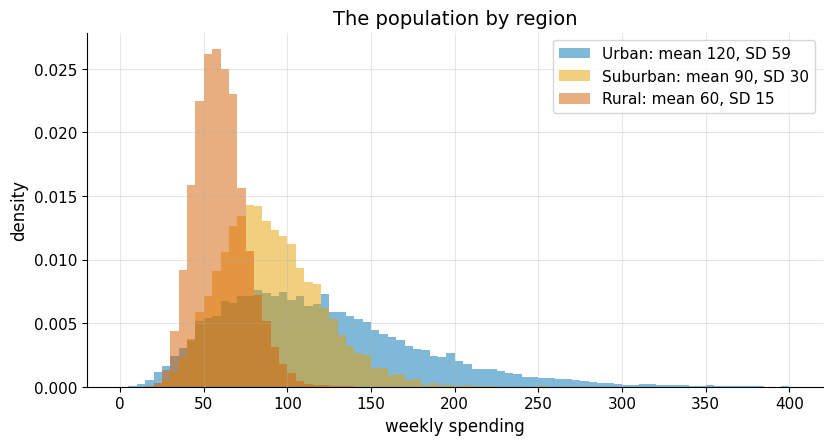

In [2]:
N_h = np.array([15_000, 9_000, 6_000]); mu_h = np.array([120.0, 90.0, 60.0]); sd_h = np.array([60.0, 30.0, 15.0])
names = ["Urban", "Suburban", "Rural"]
pop_rng = np.random.default_rng(2026)
strata = [pop_rng.gamma((m / s) ** 2, s**2 / m, size=n_) for m, s, n_ in zip(mu_h, sd_h, N_h)]
y = np.concatenate(strata); region = np.repeat([0, 1, 2], N_h); N = y.size
W = N_h / N; S_h = np.array([s.std(ddof=1) for s in strata]); M_h = np.array([s.mean() for s in strata])
mu = y.mean(); S2 = y.var(ddof=1)
print(f"N = {N:,}; population mean {mu:.3f}; population variance S^2 = {S2:.1f}")
print(pd.DataFrame({"region": names, "W": W, "mean": M_h, "SD": S_h}).round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(9.5, 4.6))
for s, nm, c in zip(strata, names, [MAIN, SIM, HIGHLIGHT]):
    ax.hist(s, bins=80, range=(0, 400), density=True, alpha=0.5, color=c, label=f"{nm}: mean {s.mean():.0f}, SD {s.std():.0f}")
ax.set_xlabel("weekly spending"); ax.set_ylabel("density"); ax.set_title("The population by region"); ax.legend()
plt.show()

### 7.2 Sampling distributions of the mean under three designs
3,000 repeated samples of $n=600$: simple random, stratified proportional, stratified Neyman. All are unbiased; the spreads differ.

allocations: proportional [300 180 120] | Neyman [429 128  43]
simulated SE: SRS 2.040 | proportional 1.849 | Neyman 1.670 | truth 98.81


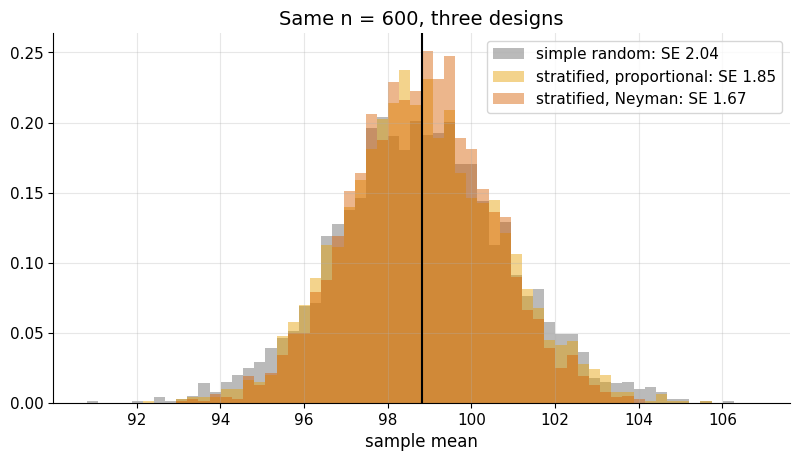

In [3]:
n = 600
def alloc_prop(n):
    a = np.round(n * W).astype(int); a[-1] += n - a.sum(); return a
def alloc_neyman(n):
    a = np.round(n * W * S_h / np.sum(W * S_h)).astype(int); a[0] += n - a.sum(); return a
def one_stratified(rng_, sizes):
    return sum(W[h] * rng_.choice(strata[h], sizes[h], replace=False).mean() for h in range(3))
des_rng = np.random.default_rng(5)
reps = 3000
n_prop, n_ney = alloc_prop(n), alloc_neyman(n)
est_srs = np.array([y[des_rng.choice(N, n, replace=False)].mean() for _ in range(reps)])
est_prop = np.array([one_stratified(des_rng, n_prop) for _ in range(reps)])
est_ney = np.array([one_stratified(des_rng, n_ney) for _ in range(reps)])
print("allocations:", "proportional", n_prop, "| Neyman", n_ney)
print(f"simulated SE: SRS {est_srs.std():.3f} | proportional {est_prop.std():.3f} | Neyman {est_ney.std():.3f} | truth {mu:.2f}")
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for e, nm, c in [(est_srs, "simple random", NEUTRAL), (est_prop, "stratified, proportional", SIM), (est_ney, "stratified, Neyman", HIGHLIGHT)]:
    ax.hist(e, bins=60, range=(mu - 8, mu + 8), density=True, alpha=0.45, color=c, label=f"{nm}: SE {e.std():.2f}")
ax.axvline(mu, color="black"); ax.set_xlabel("sample mean"); ax.set_title("Same n = 600, three designs"); ax.legend()
plt.show()

### 7.3 How should we split 600 interviews? The variance as a function of the allocation
Variance of the stratified mean when the Urban share of the sample varies from 5 % to 90 % (the other two strata split the rest in the Neyman ratio). The minimum sits at the Neyman allocation, not at the proportional one.

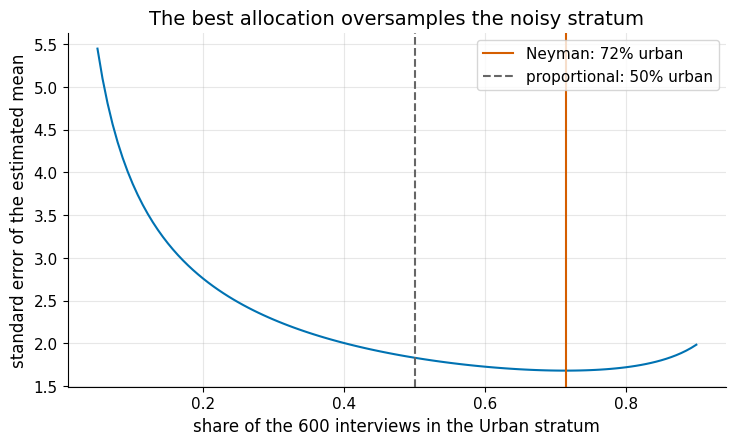

In [4]:
def var_strat(sizes, n_total=None):
    sizes = np.asarray(sizes, float)
    return np.sum(W**2 * S_h**2 / sizes * (1 - sizes / N_h))
shares = np.linspace(0.05, 0.9, 120)
rest = W[1:] * S_h[1:] / np.sum(W[1:] * S_h[1:])
v_curve = np.array([var_strat(n * np.array([s_, *((1 - s_) * rest)])) for s_ in shares])
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(shares, np.sqrt(v_curve), color=MAIN)
ax.axvline(n_ney[0] / n, color=HIGHLIGHT, label=f"Neyman: {n_ney[0] / n:.0%} urban"); ax.axvline(W[0], color=NEUTRAL, linestyle="--", label=f"proportional: {W[0]:.0%} urban")
ax.set_xlabel("share of the 600 interviews in the Urban stratum"); ax.set_ylabel("standard error of the estimated mean"); ax.set_title("The best allocation oversamples the noisy stratum"); ax.legend()
plt.show()
assert abs(shares[np.argmin(v_curve)] - n_ney[0] / n) < 0.02

### 7.4 Cluster sampling: more households per village, less information per household
Villages ($M=200$) of $K$ households with intraclass correlation $\rho$; total interviews fixed at $n=500$. Left: the design effect $1+(K-1)\rho$. Right: the standard error against households per village (the SRS standard error is the floor).

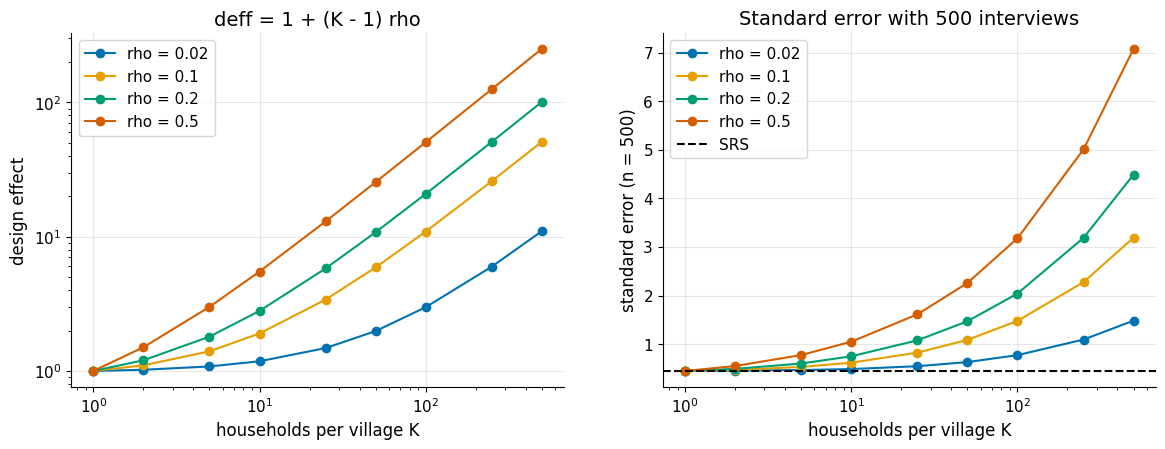

In [5]:
Ks = np.array([1, 2, 5, 10, 25, 50, 100, 250, 500])
sigma2 = 100.0
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for rho, c in zip([0.02, 0.1, 0.2, 0.5], COLORS):
    axes[0].plot(Ks, 1 + (Ks - 1) * rho, "o-", color=c, label=f"rho = {rho}")
    axes[1].plot(Ks, np.sqrt(sigma2 / 500 * (1 + (Ks - 1) * rho)), "o-", color=c, label=f"rho = {rho}")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_xlabel("households per village K"); axes[0].set_ylabel("design effect"); axes[0].set_title("deff = 1 + (K - 1) rho"); axes[0].legend()
axes[1].set_xscale("log"); axes[1].set_xlabel("households per village K"); axes[1].set_ylabel("standard error (n = 500)"); axes[1].axhline(np.sqrt(sigma2 / 500), color="black", linestyle="--", label="SRS"); axes[1].set_title("Standard error with 500 interviews"); axes[1].legend()
plt.show()

### 7.5 A bigger biased sample does not converge to the truth
Error of the mean as $n$ grows: a simple random sample (error shrinks like $1/\sqrt n$) against a **self-selected** sample where the chance of participating is proportional to spending (error settles at a bias of $\sigma^2/\mu$).

    n  SRS mean error  SRS RMSE  self-selected mean error  self-selected RMSE
   50            0.11      6.74                     27.22               28.68
  200            0.11      3.33                     26.46               26.79
 1000           -0.08      1.51                     26.38               26.46
 5000           -0.02      0.70                     26.50               26.51
20000           -0.01      0.20                     26.49               26.49
theory: self-selected limit = sigma^2 / mu = 26.49


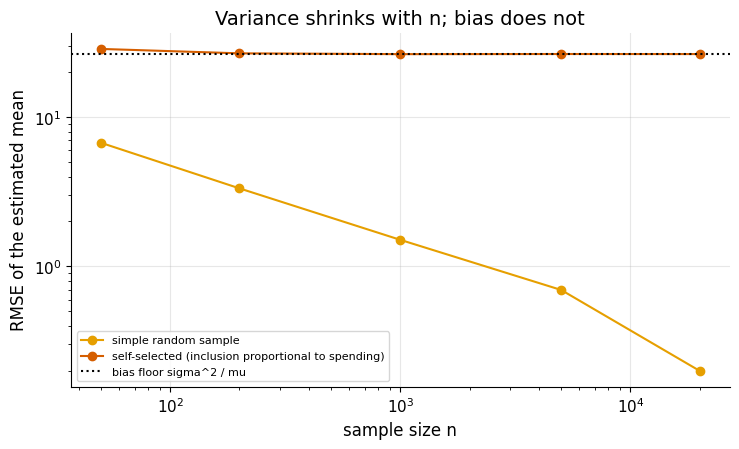

In [6]:
sel_rng = np.random.default_rng(9)
ns = [50, 200, 1000, 5000, 20_000]
p_sel = y / y.sum()
rows = []
for nn in ns:
    srs_err = np.array([y[sel_rng.choice(N, nn, replace=False)].mean() - mu for _ in range(200)])
    sel_err = np.array([y[sel_rng.choice(N, nn, replace=True, p=p_sel)].mean() - mu for _ in range(200)])
    rows.append({"n": nn, "SRS mean error": srs_err.mean(), "SRS RMSE": np.sqrt(np.mean(srs_err**2)), "self-selected mean error": sel_err.mean(), "self-selected RMSE": np.sqrt(np.mean(sel_err**2))})
sel = pd.DataFrame(rows); print(sel.round(2).to_string(index=False))
print(f"theory: self-selected limit = sigma^2 / mu = {(y.var() / mu):.2f}")
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.loglog(sel.n, sel["SRS RMSE"], "o-", color=SIM, label="simple random sample"); ax.loglog(sel.n, sel["self-selected RMSE"], "o-", color=HIGHLIGHT, label="self-selected (inclusion proportional to spending)")
ax.axhline(y.var() / mu, color="black", linestyle=":", label="bias floor sigma^2 / mu"); ax.set_xlabel("sample size n"); ax.set_ylabel("RMSE of the estimated mean"); ax.set_title("Variance shrinks with n; bias does not"); ax.legend(fontsize=8)
plt.show()
assert abs(sel["self-selected mean error"].iloc[-1] - y.var() / mu) < 1.0 and sel["SRS RMSE"].iloc[-1] < 1.0

### 7.6 Systematic sampling: a trend helps, a cycle ruins it
Three daily series of 1,001 days: random order, a smooth trend, and a weekly cycle. Sampling every 7th day from a random start: the spread of the estimated mean relative to a simple random sample of the same size (about 143 days).

In [7]:
T_days = 1001; t_ = np.arange(T_days)
series = {"random order": rng.normal(100, 10, T_days),
          "smooth trend": 80 + 0.04 * t_ + rng.normal(0, 3, T_days),
          "weekly cycle": 100 + 20 * np.sin(2 * np.pi * t_ / 7) + rng.normal(0, 3, T_days)}
rows = []
for name, s in series.items():
    k = 7; starts = np.arange(k)
    sys_means = np.array([s[st::k].mean() for st in starts])
    n_s = len(s[0::k])
    srs_sd = s.std(ddof=1) / np.sqrt(n_s) * np.sqrt(1 - n_s / T_days)
    rows.append({"series": name, "true mean": s.mean(), "SD of systematic means (7 starts)": np.sqrt(np.mean((sys_means - s.mean()) ** 2)), "SE of an SRS of the same size": srs_sd})
syst = pd.DataFrame(rows); syst["ratio systematic / SRS"] = syst.iloc[:, 2] / syst.iloc[:, 3]
print(syst.round(3).to_string(index=False))
assert syst.loc[1, "ratio systematic / SRS"] < 0.6 and syst.loc[2, "ratio systematic / SRS"] > 0.9

      series  true mean  SD of systematic means (7 starts)  SE of an SRS of the same size  ratio systematic / SRS
random order     99.711                              0.550                          0.765                   0.719
smooth trend     99.753                              0.275                          0.910                   0.303
weekly cycle    100.116                             14.131                          1.120                  12.619


## 8. 3D visuals

### 8.1 Static: the design effect over $(K,\rho)$
$\mathrm{deff}=1+(K-1)\rho$ is a plane in $(K,\rho)$: bigger clusters and stronger within-cluster similarity both multiply the variance. The surface shows how fast the effective sample size collapses ($n_{\text{eff}}=n/\mathrm{deff}$ with $n=500$).

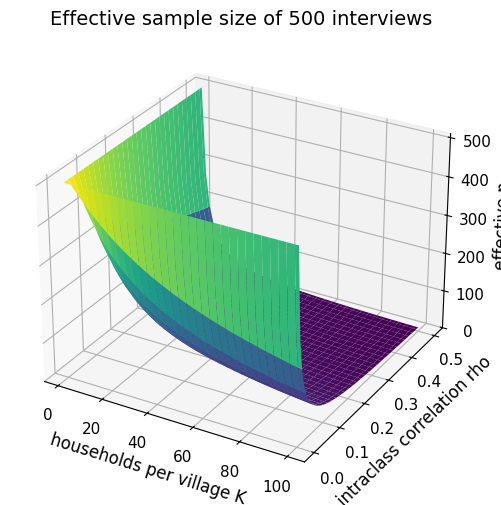

In [8]:
K_ax = np.linspace(1, 100, 60); rho_ax = np.linspace(0, 0.5, 60)
Kg, Rg = np.meshgrid(K_ax, rho_ax)
neff = 500 / (1 + (Kg - 1) * Rg)
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Kg, Rg, neff, cmap="viridis", edgecolor="none")
ax.set_title("Effective sample size of 500 interviews"); ax.set_xlabel("households per village K"); ax.set_ylabel("intraclass correlation rho"); ax.set_zlabel("effective n")
ax.view_init(elev=28, azim=-60)
plt.show()

### 8.2 Interactive Plotly version of 8.1
Hover to read the effective sample size for any cluster size and correlation.

In [9]:
fig = go.Figure(go.Surface(x=K_ax, y=rho_ax, z=neff, colorscale="Viridis"))
fig.update_layout(title="Effective sample size = 500 / (1 + (K - 1) rho)", width=750, height=550, scene=dict(xaxis_title="K", yaxis_title="rho", zaxis_title="effective n"))
fig.show()

### 8.3 Static: the standard error over the allocation of the 600 interviews (Urban share, Suburban share)
The remaining share goes to Rural. The surface is a bowl; its lowest point is the Neyman allocation.

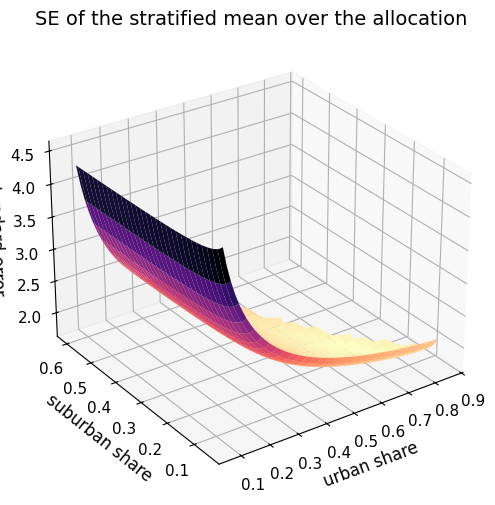

minimum SE 1.680 at urban 0.72, suburban 0.21 (Neyman: 0.71, 0.21)


In [10]:
s1 = np.linspace(0.08, 0.85, 60); s2 = np.linspace(0.05, 0.6, 60)
S1, S2g = np.meshgrid(s1, s2)
SEg = np.full(S1.shape, np.nan)
for i in range(S1.shape[0]):
    for j in range(S1.shape[1]):
        s3 = 1 - S1[i, j] - S2g[i, j]
        if s3 > 0.02:
            SEg[i, j] = np.sqrt(var_strat(n * np.array([S1[i, j], S2g[i, j], s3])))
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(S1, S2g, np.ma.masked_invalid(SEg), cmap="magma_r", edgecolor="none")
ax.set_title("SE of the stratified mean over the allocation"); ax.set_xlabel("urban share"); ax.set_ylabel("suburban share"); ax.set_zlabel("standard error")
ax.view_init(elev=28, azim=-125)
plt.show()
best = np.unravel_index(np.nanargmin(SEg), SEg.shape)
print(f"minimum SE {np.nanmin(SEg):.3f} at urban {S1[best]:.2f}, suburban {S2g[best]:.2f} (Neyman: {n_ney[0] / n:.2f}, {n_ney[1] / n:.2f})")
assert abs(S1[best] - n_ney[0] / n) < 0.03 and abs(S2g[best] - n_ney[1] / n) < 0.03

## 9. Simulation vs theory

### 9.1 Stratified variances: formulas against 3,000 simulated surveys

In [11]:
f = n / N
v_srs = S2 / n * (1 - f)
v_prop = (1 - f) / n * np.sum(W * S_h**2)
v_ney_formula = np.sum(W * S_h) ** 2 / n - np.sum(W * S_h**2) / N
v_prop_exact, v_ney_exact = var_strat(n_prop), var_strat(n_ney)
tab = pd.DataFrame({"design": ["simple random", "stratified proportional", "stratified Neyman"],
                    "theory SE": np.sqrt([v_srs, v_prop_exact, v_ney_exact]), "simulated SE": [est_srs.std(), est_prop.std(), est_ney.std()]})
print(tab.round(4).to_string(index=False))
print(f"approximate formulas: proportional {np.sqrt(v_prop):.4f}, Neyman {np.sqrt(v_ney_formula):.4f}")
assert np.allclose(tab["theory SE"], tab["simulated SE"], rtol=0.06)

                 design  theory SE  simulated SE
          simple random     2.0678        2.0402
stratified proportional     1.8429        1.8486
      stratified Neyman     1.6801        1.6704
approximate formulas: proportional 1.8429, Neyman 1.6801


### 9.2 The cluster design effect on a simulated population
Population of 2,000 villages with 50 households each, $\sigma_b^2=20$ and $\sigma_w^2=80$ (so $\rho=0.2$). Compare 10 villages of 50 households with an SRS of 500 households.

In [12]:
cl_rng = np.random.default_rng(14)
M_v, K_v = 2000, 50
village = cl_rng.normal(0, np.sqrt(20), M_v)
yc = 50 + village[:, None] + cl_rng.normal(0, np.sqrt(80), (M_v, K_v))
mu_c = yc.mean(); sig2 = yc.var(ddof=1)
reps = 4000
m = 10
est_cl = np.array([yc[cl_rng.choice(M_v, m, replace=False)].mean() for _ in range(reps)])
flat = yc.ravel()
est_sr = np.array([flat[cl_rng.choice(flat.size, m * K_v, replace=False)].mean() for _ in range(reps)])
deff_sim = est_cl.var() / est_sr.var()
print(f"SE cluster {est_cl.std():.3f} | SE SRS {est_sr.std():.3f} | simulated deff {deff_sim:.2f} | theory 1 + (K - 1) rho = {1 + (K_v - 1) * 0.2:.2f}")
print(f"effective sample size of the 500 interviews: {500 / deff_sim:.0f}")
assert abs(deff_sim - 10.8) < 1.8

SE cluster 1.435 | SE SRS 0.441 | simulated deff 10.59 | theory 1 + (K - 1) rho = 10.80
effective sample size of the 500 interviews: 47


### 9.3 Kish design effect of weights
Weights $1/\pi$ with three levels (10, 20, 50) held by 62.5 %, 31.25 % and 6.25 % of respondents: the formula $n\sum w^2/(\sum w)^2$ against the simulated variance inflation of a weighted mean.

In [13]:
w_levels = np.array([10.0, 20.0, 50.0]); share = np.array([0.625, 0.3125, 0.0625])
kish = np.sum(share * w_levels**2) / np.sum(share * w_levels) ** 2
w_rng = np.random.default_rng(23)
nn = 2000; reps = 4000
grp = w_rng.choice(3, size=(reps, nn), p=share)
yy = w_rng.normal(0, 1, (reps, nn))                         # outcome unrelated to the weights
w = w_levels[grp]
weighted_mean = (w * yy).sum(axis=1) / w.sum(axis=1)
infl = weighted_mean.var() / (1 / nn)
print(f"Kish deff {kish:.3f} | simulated variance inflation of the weighted mean {infl:.3f}")
assert abs(infl - kish) < 0.06

Kish deff 1.408 | simulated variance inflation of the weighted mean 1.436


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [14]:
df = pd.DataFrame({"region": region, "y": y})
print("stratified sample with pandas, proportional 1 %:", df.groupby("region").sample(frac=0.01, random_state=1).region.value_counts().sort_index().to_dict())
print("stratified sample with fixed sizes:", df.groupby("region").sample(n=20, random_state=1).region.value_counts().sort_index().to_dict(), "(pass a dict via groupby.apply for unequal sizes)")
print("weighted mean: np.average(values, weights=w) ->", round(np.average([7, 6, 5], weights=[0.625, 0.3125, 0.0625]), 4), "| Kish n_eff:", round(1000 / kish, 1), "from n = 1000")
print("systematic sample: s[start::k]; random start: rng.integers(k) ->", np.arange(30)[3::7])
print("cluster sample (pandas): ids = rng.choice(df.cluster.unique(), m, replace=False); df[df.cluster.isin(ids)]")
print("sklearn (not required here): StratifiedShuffleSplit / train_test_split(stratify=y) for stratified splits; GroupKFold for clustered data")
print("design-based standard error with scipy: stats.sem(values) for SRS; multiply by sqrt(1 - n/N) and sqrt(deff)")

stratified sample with pandas, proportional 1 %: {0: 150, 1: 90, 2: 60}
stratified sample with fixed sizes: {0: 20, 1: 20, 2: 20} (pass a dict via groupby.apply for unequal sizes)
weighted mean: np.average(values, weights=w) -> 6.5625 | Kish n_eff: 710.2 from n = 1000
systematic sample: s[start::k]; random start: rng.integers(k) -> [ 3 10 17 24]
cluster sample (pandas): ids = rng.choice(df.cluster.unique(), m, replace=False); df[df.cluster.isin(ids)]
sklearn (not required here): StratifiedShuffleSplit / train_test_split(stratify=y) for stratified splits; GroupKFold for clustered data
design-based standard error with scipy: stats.sem(values) for SRS; multiply by sqrt(1 - n/N) and sqrt(deff)


## 11. Real-world worked examples

---
### Example 1 (main): how to split 600 interviews across three regions

**Scenario.** A market-research team will interview **$n=600$** of the $N=30{,}000$ households of the city of Section 7.1 about weekly spending. Regions differ: Urban ($W=0.5$, SD about 60), Suburban ($W=0.3$, SD 30), Rural ($W=0.2$, SD 15). Interviews cost the same everywhere.

**Questions**
1. What is the standard error of the estimated city mean under **simple random sampling**?
2. Under **proportional** stratified sampling?
3. What is the **Neyman allocation**, and the resulting standard error? How much does it save in *interviews*?
4. Check all three by simulation.

### 11.1 By hand
Overall mean $\mu=0.5\cdot120+0.3\cdot90+0.2\cdot60=99$. Within-strata variance $\sum W_hS_h^2=0.5\cdot3600+0.3\cdot900+0.2\cdot225=2115$; between-strata $\sum W_h(\mu_h-\mu)^2=0.5\cdot441+0.3\cdot81+0.2\cdot1521=549$; total $S^2\approx2664$.

**Q1.** $\mathrm{SE}_{SRS}=\sqrt{2664/600}\times\sqrt{1-0.02}=2.107\times0.99=2.09$.

**Q2.** $\mathrm{SE}_{prop}=\sqrt{2115/600}\times0.99=1.877\times0.99=1.86$ (the between-strata 549 is gone).

**Q3.** $W_hS_h=(30,\,9,\,3)$, sum 42, so $n_h=600\cdot(30,9,3)/42=(428.6,\,128.6,\,42.9)$, i.e. about **(429, 129, 43)**. Variance $=42^2/600=2.94$, $\mathrm{SE}_{Ney}\approx1.71$ (minus a small finite-population term). **Interviews saved:** to get the SRS precision with Neyman allocation we need $n=600\cdot1.71^2/2.09^2\approx402$, i.e. **about one third fewer**.

In [15]:
se_srs = np.sqrt(S2 / n * (1 - n / N))
se_prop = np.sqrt(var_strat(n_prop)); se_ney = np.sqrt(var_strat(n_ney))
print(f"population: mean {mu:.2f}, S^2 = {S2:.0f}; within {np.sum(W * S_h**2):.0f}, between {np.sum(W * (M_h - mu)**2):.0f}")
print(f"Q1 SRS SE {se_srs:.3f} | Q2 proportional SE {se_prop:.3f} | Q3 Neyman SE {se_ney:.3f}, allocation {n_ney}")
n_equiv = n * (se_ney / se_srs) ** 2
print(f"Neyman with n = {n} matches an SRS of n = {n / (se_ney / se_srs) ** 2:.0f}; to match the SRS(600) SE the Neyman design needs only {n_equiv:.0f} interviews ({1 - n_equiv / n:.0%} fewer)")

population: mean 98.81, S^2 = 2618; within 2079, between 539
Q1 SRS SE 2.068 | Q2 proportional SE 1.843 | Q3 Neyman SE 1.680, allocation [429 128  43]
Neyman with n = 600 matches an SRS of n = 909; to match the SRS(600) SE the Neyman design needs only 396 interviews (34% fewer)


### 11.2 In code with `scipy`, and the asserts

In [16]:
assert abs(mu - 99) < 0.6 and abs(se_srs - 2.09) < 0.06 and abs(se_prop - 1.86) < 0.05 and abs(se_ney - 1.71) < 0.05
assert se_ney < se_prop < se_srs
assert list(n_ney) == [429, 129, 42] or abs(n_ney[0] - 429) <= 2
assert abs(np.sum(W * S_h**2) - 2115) < 40 and abs(np.sum(W * (M_h - mu) ** 2) - 549) < 20
# the formula is the law of total variance: S^2 is within + between (approximately, N large)
assert abs(S2 - (np.sum(W * S_h**2) + np.sum(W * (M_h - mu) ** 2))) < 5
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
The 3,000 repeated surveys of Section 7.2 already contain the answer; here we also check that the three estimators are unbiased and compare with the SEs by hand.

In [17]:
print(f"mean of the 3,000 estimates: SRS {est_srs.mean():.3f}, proportional {est_prop.mean():.3f}, Neyman {est_ney.mean():.3f} (truth {mu:.3f})")
print(f"simulated SE: SRS {est_srs.std():.3f} (theory {se_srs:.3f}) | proportional {est_prop.std():.3f} ({se_prop:.3f}) | Neyman {est_ney.std():.3f} ({se_ney:.3f})")
cover = {nm: np.mean(np.abs(e - mu) <= 1.96 * s) for nm, e, s in [("SRS", est_srs, se_srs), ("prop", est_prop, se_prop), ("Neyman", est_ney, se_ney)]}
print("coverage of mean +/- 1.96 SE:", {k: round(v, 3) for k, v in cover.items()})
assert all(abs(e.mean() - mu) < 0.15 for e in (est_srs, est_prop, est_ney))
assert np.allclose([est_srs.std(), est_prop.std(), est_ney.std()], [se_srs, se_prop, se_ney], rtol=0.06)
assert all(0.93 < v < 0.97 for v in cover.values())

mean of the 3,000 estimates: SRS 98.811, proportional 98.815, Neyman 98.799 (truth 98.810)
simulated SE: SRS 2.040 (theory 2.068) | proportional 1.849 (1.843) | Neyman 1.670 (1.680)
coverage of mean +/- 1.96 SE: {'SRS': np.float64(0.949), 'prop': np.float64(0.951), 'Neyman': np.float64(0.95)}


### 11.4 Plots with the regions shaded

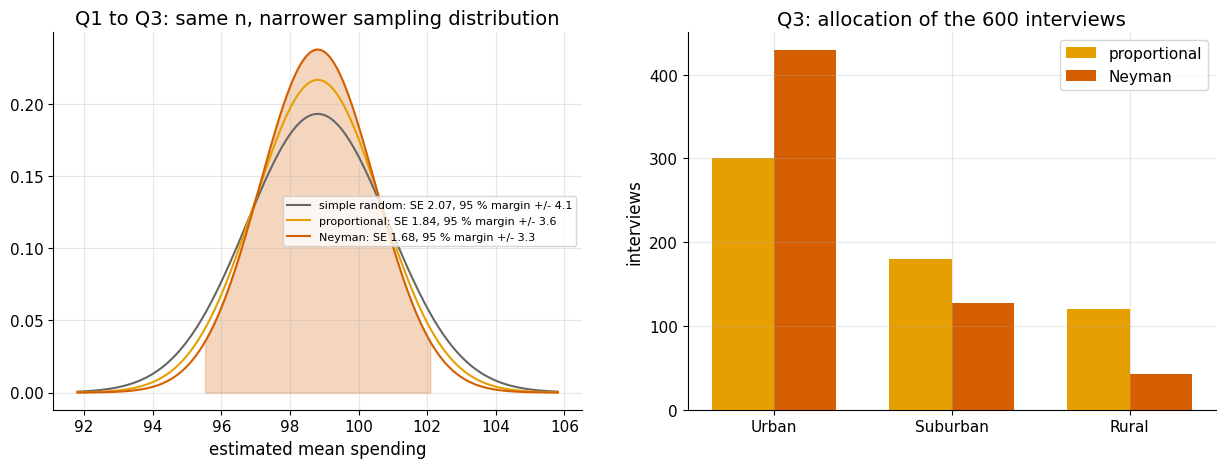

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.9))
xs = np.linspace(mu - 7, mu + 7, 400)
for se, nm, c in [(se_srs, "simple random", NEUTRAL), (se_prop, "proportional", SIM), (se_ney, "Neyman", HIGHLIGHT)]:
    axes[0].plot(xs, stats.norm.pdf(xs, mu, se), color=c, label=f"{nm}: SE {se:.2f}, 95 % margin +/- {1.96 * se:.1f}")
axes[0].fill_between(xs, 0, stats.norm.pdf(xs, mu, se_ney), where=np.abs(xs - mu) <= 1.96 * se_ney, color=HIGHLIGHT, alpha=0.25)
axes[0].set_title("Q1 to Q3: same n, narrower sampling distribution"); axes[0].set_xlabel("estimated mean spending"); axes[0].legend(fontsize=8)
x_ = np.arange(3); wd = 0.35
axes[1].bar(x_ - wd / 2, n_prop, wd, color=SIM, label="proportional"); axes[1].bar(x_ + wd / 2, n_ney, wd, color=HIGHLIGHT, label="Neyman")
axes[1].set_xticks(x_); axes[1].set_xticklabels(names); axes[1].set_ylabel("interviews"); axes[1].set_title("Q3: allocation of the 600 interviews"); axes[1].legend()
plt.show()

### 11.5 Interpretation and decision (Example 1)
- **Same 600 interviews, three different precisions.** Standard errors: simple random **2.07**, proportional stratified **1.84**, Neyman **1.68** (simulation: 2.04, 1.85, 1.67). All three are unbiased and their 95 % intervals cover the truth 95 % of the time.
- **Why.** The between-region differences (variance 539) disappear when the regional shares are fixed; Neyman then moves interviews to the noisy urban stratum (429 urban, 128 suburban, 43 rural instead of 300, 180, 120).
- **Savings.** Neyman with 600 interviews is as precise as a simple random sample of about **909**, or equivalently matches the simple-random precision with only **396** interviews, **34 % fewer**.
- **Decision.** Stratify by region and allocate in proportion to $W_hS_h$. If the regional SDs are unknown, a pilot of a few dozen households per region is enough to estimate them; proportional allocation is the safe default.

---
### Example 2: surveying villages (cluster sampling)

**Scenario.** A health survey must interview **500 households** in a region of 2,000 villages with 50 households each. Travel is costly, so the team samples **10 whole villages** (all 50 households each). Households in a village are alike: intraclass correlation $\rho=0.2$ (between-village variance 20, within 80, total 100). What does the cluster design cost in precision, and what if the team visits **50 villages with 10 households** instead?

### 11.6 By hand, in code and by simulation
**By hand.** $\mathrm{Var}=\sigma_b^2/m+\sigma_w^2/(mK)$. Design A ($m=10$, $K=50$): $20/10+80/500=2.16$, SE 1.47, $\mathrm{deff}=1+49\cdot0.2=10.8$, $n_{\text{eff}}=500/10.8=46$. Design B ($m=50$, $K=10$): $20/50+80/500=0.56$, SE 0.75, $\mathrm{deff}=1+9\cdot0.2=2.8$, $n_{\text{eff}}=179$. SRS of 500 households: $100/500=0.2$, SE 0.447.

               design  variance    SE  deff  effective n
SRS of 500 households      0.20 0.447   1.0      500.000
  A: 10 villages x 50      2.16 1.470  10.8       46.296
  B: 50 villages x 10      0.56 0.748   2.8      178.571
  C: 100 villages x 5      0.36 0.600   1.8      277.778
simulated SE of design A: 1.435 (theory 1.470) | design B: 0.723 (theory 0.748)


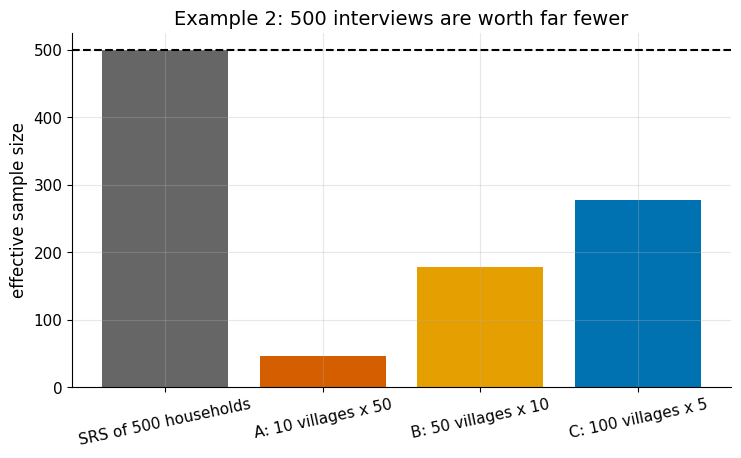

In [19]:
def cluster_var(m, K, sb2=20.0, sw2=80.0):
    return sb2 / m + sw2 / (m * K)
rows = []
for label, mm, KK in [("SRS of 500 households", None, None), ("A: 10 villages x 50", 10, 50), ("B: 50 villages x 10", 50, 10), ("C: 100 villages x 5", 100, 5)]:
    v = 100 / 500 if mm is None else cluster_var(mm, KK)
    rows.append({"design": label, "variance": v, "SE": np.sqrt(v), "deff": v / (100 / 500), "effective n": 500 / (v / (100 / 500))})
cl = pd.DataFrame(rows); print(cl.round(3).to_string(index=False))
# simulate design B on the population of Section 9.2 as well
est_B = np.array([yc[cl_rng.choice(M_v, 50, replace=False)][:, :10].mean() for _ in range(3000)])
print(f"simulated SE of design A: {est_cl.std():.3f} (theory {np.sqrt(cluster_var(10, 50)):.3f}) | design B: {est_B.std():.3f} (theory {np.sqrt(cluster_var(50, 10)):.3f})")
assert abs(cl.loc[1, "deff"] - 10.8) < 1e-9 and abs(cl.loc[2, "deff"] - 2.8) < 1e-9
assert abs(est_cl.std() - np.sqrt(cluster_var(10, 50))) < 0.2 and abs(est_B.std() - np.sqrt(cluster_var(50, 10))) < 0.1
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.bar(cl["design"], cl["effective n"], color=[NEUTRAL, HIGHLIGHT, SIM, MAIN]); ax.axhline(500, color="black", linestyle="--")
ax.set_ylabel("effective sample size"); ax.set_title("Example 2: 500 interviews are worth far fewer"); ax.tick_params(axis="x", labelrotation=12)
plt.show()

### 11.6b Interpretation and decision (Example 2)
- Sampling 10 whole villages gives SE **1.47** (simulated 1.44) against 0.447 for a simple random sample of the same 500 households: a design effect of **10.8**, so the 500 interviews carry the information of only **46** independent ones.
- Visiting **50 villages with 10 households** each (same 500 interviews) cuts the design effect to **2.8** (effective size 179), and 100 villages of 5 gives 1.8 (278). The fieldwork cost rises, so the real question is the trade-off between travel cost and variance.
- **Decision.** If travel is the main cost, take more villages with fewer households each: going from 50 to 10 households per village divides the variance by almost four.

---
### Example 3: an online satisfaction survey with unequal response (weights)

**Scenario.** A company invites a random sample of customers to rate satisfaction (0 to 10). Customer groups: Young (40 %, true mean rating 7), Middle (40 %, mean 6), Older (20 %, mean 5); true overall mean 6.2. Response rates are 10 %, 5 % and 2 %. What does the plain average of the respondents say, and what do weights do?

### 11.7 By hand, in code and by simulation
**By hand.** Respondent shares $\propto W_h\pi_h=(0.040,0.020,0.004)$, i.e. $(62.5\,\%,\,31.25\,\%,\,6.25\,\%)$. Plain mean $=0.625\cdot7+0.3125\cdot6+0.0625\cdot5=6.5625$: **bias $+0.36$**. Weights $w\propto1/\pi=(10,20,50)$ restore the shares and the mean 6.2. Kish design effect $=\sum s_hw_h^2/(\sum s_hw_h)^2=343.75/244.14=1.41$, so the weighted estimate has $41\,\%$ more variance than an unweighted sample of the same size.

true mean 6.200; respondent shares [0.625  0.3125 0.0625]; plain respondent mean 6.5625 (bias +0.3625); Kish deff 1.408


population mean in the simulated population 6.201; average respondents per survey 1280
      estimator  mean error     SD
     plain mean      0.3576 0.0443
 Hajek weighted     -0.0009 0.0578
post-stratified     -0.0031 0.0493


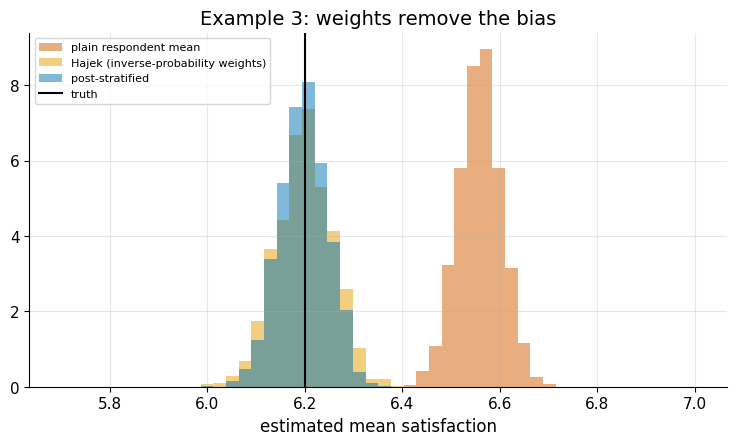

In [20]:
W3 = np.array([0.4, 0.4, 0.2]); mean3 = np.array([7.0, 6.0, 5.0]); sd3 = np.array([1.5, 1.5, 1.5]); pi3 = np.array([0.10, 0.05, 0.02])
mu3 = np.sum(W3 * mean3)
share_resp = W3 * pi3 / np.sum(W3 * pi3)
plain = np.sum(share_resp * mean3)
kish3 = np.sum(share_resp * (1 / pi3) ** 2) / np.sum(share_resp * (1 / pi3)) ** 2
print(f"true mean {mu3:.3f}; respondent shares {share_resp.round(4)}; plain respondent mean {plain:.4f} (bias {plain - mu3:+.4f}); Kish deff {kish3:.3f}")
sv_rng = np.random.default_rng(33)
N3, invited, reps = 200_000, 20_000, 1500
group = sv_rng.choice(3, N3, p=W3)
rating = np.clip(sv_rng.normal(mean3[group], sd3[group]), 0, 10)
true3 = rating.mean()
plain_e, hajek_e, post_e = [], [], []
for _ in range(reps):
    inv = sv_rng.choice(N3, invited, replace=False)
    resp = inv[sv_rng.random(invited) < pi3[group[inv]]]
    g, r = group[resp], rating[resp]
    w = 1 / pi3[g]
    plain_e.append(r.mean()); hajek_e.append(np.sum(w * r) / np.sum(w))
    post_e.append(sum(W3[k] * r[g == k].mean() for k in range(3)))
res = pd.DataFrame({"estimator": ["plain mean", "Hajek weighted", "post-stratified"], "mean error": [np.mean(plain_e) - true3, np.mean(hajek_e) - true3, np.mean(post_e) - true3],
                    "SD": [np.std(plain_e), np.std(hajek_e), np.std(post_e)]})
print(f"population mean in the simulated population {true3:.3f}; average respondents per survey {np.mean([0]) + invited * np.sum(W3 * pi3):.0f}")
print(res.round(4).to_string(index=False))
assert abs(plain - 6.5625) < 1e-9 and abs(kish3 - 1.408) < 0.002
assert abs(np.mean(plain_e) - true3 - 0.36) < 0.04 and abs(np.mean(hajek_e) - true3) < 0.01 and abs(np.mean(post_e) - true3) < 0.01
fig, ax = plt.subplots(figsize=(9, 4.6))
for e, nm, c in [(plain_e, "plain respondent mean", HIGHLIGHT), (hajek_e, "Hajek (inverse-probability weights)", SIM), (post_e, "post-stratified", MAIN)]:
    ax.hist(e, bins=50, range=(true3 - 0.5, true3 + 0.8), density=True, alpha=0.5, color=c, label=nm)
ax.axvline(true3, color="black", label="truth"); ax.set_xlabel("estimated mean satisfaction"); ax.set_title("Example 3: weights remove the bias"); ax.legend(fontsize=8)
plt.show()

### 11.7b Interpretation and decision (Example 3)
- Younger customers answer more often, so the plain respondent mean (6.56) overstates satisfaction by **0.36 points**; in 1,500 simulated surveys the plain mean was off by +0.358 on average, and no larger invitation list would fix it.
- Weighting each respondent by $1/\pi$ (Hajek) or post-stratifying removes the bias (errors $-0.001$ and $-0.003$). The price is variance: the SD rises from 0.044 to 0.058 (Hajek), a variance inflation of 1.44 against the Kish prediction 1.41, so 1,000 respondents are worth about 710.
- **Decision.** Always report the weighted estimate and its (larger) standard error; with a non-response pattern this strong the unweighted number is misleading.

## 12. Where it is used

### Statistics
- **Survey sampling** (household, labour-force, health and election polls): stratification, clustering, weighting, post-stratification, design effects, **effective sample size**.
- **Experimental design:** blocking is stratification, cluster-randomised trials are cluster sampling with design effect $1+(K-1)\rho$; sample-size calculations multiply by deff.

### Data science
- **A/B testing** with user-level randomisation versus cluster (store, market) randomisation; stratified randomisation to balance covariates; **sampling logs** for monitoring (systematic or stratified by segment).
- **Reweighting** non-representative panels, post-stratification of online surveys, "who is missing" audits; Example 3.

### ML and AI
- **Stratified train/validation/test splits** (keep class proportions; essential for imbalanced classes), **group-aware cross-validation** (all rows of a user, patient or document in the same fold: otherwise leakage, the cluster effect in disguise).
- **Importance weighting** under covariate shift, **active learning** and data selection (sampling probabilities and inverse weights), the **effective sample size** of correlated or weighted data (also used in importance sampling and sequential Monte Carlo).
- **Dataset bias:** a huge but self-selected web corpus can have bias that no amount of data removes (Section 7.5).

## 13. Common pitfalls and misconceptions

- **A big sample is not a good sample.** Variance falls with $n$, selection bias does not (7.5).
- **Ignoring clustering** makes standard errors far too small: 500 interviews in 10 villages are worth about 46 (Example 2). Use cluster-robust errors.
- **Stratify on variables that predict the outcome**, and only if their population shares are known; strata unrelated to $y$ give no gain (but no harm).
- **Neyman needs the stratum SDs**, usually unknown; use pilot data or the proportional allocation as a safe default.
- **Weights are not free:** extreme weights inflate variance (Kish); trim or smooth them, and never weight on outcomes you are measuring.
- **Systematic sampling and periodicity:** never take every 7th day from a weekly series.
- **Post-stratification needs the population shares**; with wrong shares you trade one bias for another.
- **Finite population correction** matters only when $n/N$ is not small (here 2 %); ignoring it is conservative.
- **Convenience samples** (volunteers, app users) can be reweighted only for the traits you observe; unobserved reasons for participation remain.

## 14. Exercises

1. A population has two strata: $W_1=0.8$, $S_1=10$; $W_2=0.2$, $S_2=40$. For $n=400$ compute the SE under proportional and Neyman allocation. Which stratum gets the extra interviews and by how much?
2. For Example 2, how many villages $m$ of $K=10$ households are needed to reach an SE of 0.5? And with $K=50$?
3. A school-based survey samples 20 schools with 30 pupils each ($\rho=0.05$). What are the design effect and the effective sample size of the 600 pupils? What if $\rho=0.3$?
4. In Example 3, what would the plain respondent mean be if the response rates were 10 %, 10 % and 10 %? And if they were 10 %, 8 % and 2 %?
5. A weekly series has a Monday spike. Explain why sampling every 7th day (random start) gives a wrong *picture* of each estimate yet an unbiased estimator of the mean, and why its variance is nevertheless large.
6. (Harder) Verify by simulation that the Hajek estimator with *estimated* weights (response rates estimated from the respondents' own group sizes) has approximately the same bias and variance as with the known weights of Example 3.

Solutions are at the end.

## 15. Summary table

| Design | Gain | Cost | Variance / effect |
|---|---|---|---|
| Simple random | baseline | needs a full list | $S^2(1-f)/n$ |
| Stratified (proportional) | removes the between-strata variance | needs strata shares | $(1-f)\sum W_hS_h^2/n$ |
| Stratified (Neyman) | best for fixed $n$ | needs stratum SDs | $(\sum W_hS_h)^2/n$ |
| Cluster | cheap fieldwork | $\mathrm{deff}=1+(K-1)\rho$ | effective $n=n/\mathrm{deff}$ |
| Systematic | cheap, spreads over a list | fails on periodic lists | depends on ordering |
| Weighting | removes selection bias | $\mathrm{deff}_w=1+\mathrm{CV}^2$ | Horvitz-Thompson, Hajek |

## Solutions

In [21]:
W2, S2s, n2 = np.array([0.8, 0.2]), np.array([10.0, 40.0]), 400
prop_se = np.sqrt(np.sum(W2 * S2s**2) / n2); ney_se = np.sum(W2 * S2s) / np.sqrt(n2)
ney_n = n2 * W2 * S2s / np.sum(W2 * S2s)
print(f"1: proportional SE {prop_se:.3f}, Neyman SE {ney_se:.3f}; allocation proportional {n2 * W2} vs Neyman {ney_n} (stratum 2 gets {ney_n[1] - n2 * W2[1]:.0f} more)")
print("2: K = 10:", int(np.ceil((20 + 80 / 10) / 0.25)), "villages | K = 50:", int(np.ceil((20 + 80 / 50) / 0.25)), "villages")
for rho in (0.05, 0.3):
    d = 1 + 29 * rho
    print(f"3: rho = {rho}: deff {d:.2f}, effective sample size {600 / d:.0f}")
sh = lambda pi: (W3 * np.array(pi)) / np.sum(W3 * np.array(pi))
print("4: equal rates:", round(float(np.sum(sh([0.1, 0.1, 0.1]) * mean3)), 3), "| rates 10/8/2 %:", round(float(np.sum(sh([0.10, 0.08, 0.02]) * mean3)), 3))
sys_rng = np.random.default_rng(3)
day = np.arange(1001); sales = 100 + 30 * (day % 7 == 0) + sys_rng.normal(0, 3, 1001)
sm = np.array([sales[s::7].mean() for s in range(7)])
print(f"5: the 7 possible systematic means: min {sm.min():.1f}, max {sm.max():.1f}, truth {sales.mean():.1f}; average of the 7 = {sm.mean():.2f} (unbiased) but the spread across starts is {sm.std():.1f}")
est_known, est_est = [], []
for _ in range(600):
    inv = sv_rng.choice(N3, invited, replace=False); resp = inv[sv_rng.random(invited) < pi3[group[inv]]]
    g, r = group[resp], rating[resp]
    est_known.append(np.sum(r / pi3[g]) / np.sum(1 / pi3[g]))
    pi_hat = np.array([(g == k).sum() / (invited * W3[k]) for k in range(3)])         # estimated response rate of each group
    est_est.append(np.sum(r / pi_hat[g]) / np.sum(1 / pi_hat[g]))
print(f"6: known weights: error {np.mean(est_known) - true3:+.4f}, SD {np.std(est_known):.4f} | estimated weights: error {np.mean(est_est) - true3:+.4f}, SD {np.std(est_est):.4f}")

1: proportional SE 1.000, Neyman SE 0.800; allocation proportional [320.  80.] vs Neyman [200. 200.] (stratum 2 gets 120 more)
2: K = 10: 112 villages | K = 50: 87 villages
3: rho = 0.05: deff 2.45, effective sample size 245
3: rho = 0.3: deff 9.70, effective sample size 62
4: equal rates: 6.2 | rates 10/8/2 %: 6.474
5: the 7 possible systematic means: min 99.7, max 130.0, truth 104.4; average of the 7 = 104.40 (unbiased) but the spread across starts is 10.4


6: known weights: error +0.0010, SD 0.0584 | estimated weights: error -0.0002, SD 0.0508


**1.** Proportional SE 1.000, Neyman SE 0.800. Neyman gives (200, 200) instead of (320, 80): stratum 2 receives **120 more** interviews because its SD is four times larger.

**2.** With $K=10$: $m=(20+8)/0.25=112$ villages (1,120 households); with $K=50$: $m=(20+1.6)/0.25=87$ villages (4,350 households). Bigger clusters need fewer villages but far more interviews.

**3.** $\rho=0.05$: deff $=1+29\cdot0.05=2.45$, effective size 245. $\rho=0.3$: deff 9.7, effective size 62.

**4.** With equal rates the respondents are representative and the mean is 6.2. With rates 10 %, 8 %, 2 % the mean is 6.47 (bias +0.27).

**5.** Each start picks one of 7 weekdays, so some systematic samples contain only Mondays (mean 130) and others none (99.7); the average of the seven is 104.4, the truth, hence unbiased, but the spread across starts is 10.4, a huge variance, because the sampling interval matches the weekly cycle.

**6.** Known weights: error $+0.001$, SD 0.058. Estimated weights: error $-0.000$, SD 0.051. The estimated-weight version is unbiased and, if anything, slightly steadier (estimating the response rates from the realised group sizes also corrects chance imbalance).